# ECG Heartbeat CBM, CEM & Per-Timestamp Dense Soft-Segmentation — Inference Showcase

This notebook demonstrates the three interpretable model families in this repository on unseen **PTB-XL Test Fold 10** 12-lead ECGs:

1. **Window-Level CBM + RandInt** (`models/cbm_softseg`) — scalar concept bottleneck (`P, Q, R, S, T, U, PR, QRS, ST, QT`) with heteroscedastic + MC-Dropout uncertainty.
2. **Window-Level CEM** (`models/cem_softseg`) — Concept Embedding Model with per-concept positive/negative embeddings, high intervention efficacy, and counterfactual faithfulness.
3. **Per-Timestamp Dense 1D U-Net CBM & CEM** (`models/dense_cbm_softseg`, `models/dense_cem_softseg`) — 100 Hz (`10 ms`) per-timestamp soft wave segmentation (`P, PQ, QRS, ST, T, TP`), boundary-aware uncertainty `σ(t)`, and downstream 5-class cardiac pathology prediction (`NORM, MI, STTC, CD, HYP`) with live temporal mask interventions.

> **Data Exploration**: For comprehensive PTB-XL data quality, artifact audits, and Zenodo 7610236 delineation benchmarks, see [explainable-ecg-learning/ecg-data-repo](https://github.com/explainable-ecg-learning/ecg-data-repo).

In [1]:
import ast
import json
import sys
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import wfdb
import yaml

# Resolve repository, data & default model paths from config.yaml
REPO_ROOT = Path.cwd()
with open(REPO_ROOT / "config.yaml") as f:
    ROOT_CFG = yaml.safe_load(f)
DATA_CFG = ROOT_CFG["data"]
INF_CFG  = ROOT_CFG.get("inference", {})

sys.path.insert(0, str(REPO_ROOT / "src"))

from data import bandpass_filter, get_concept_labels, is_complete_heartbeat_window, z_normalize
from dense_seg import SUPERCLASS_NAMES, WAVE6_NAMES, build_dense_model, collapse_soft_seg_targets
from models import CONCEPT_NAMES, build_model
from soft_seg import SoftSegArchive, extract_fiducials_from_soft_seg, soft_seg_to_wave_curves

DATA_DIR      = Path(DATA_CFG["data_dir"])
DATA_PATH     = Path(DATA_CFG["data_path"]) if Path(DATA_CFG["data_path"]).is_absolute() else DATA_DIR / DATA_CFG["data_path"]
SOFT_SEG_PATH = Path(DATA_CFG["soft_seg_path"]) if Path(DATA_CFG["soft_seg_path"]).is_absolute() else DATA_DIR / DATA_CFG["soft_seg_path"]

CBM_DIR       = REPO_ROOT / INF_CFG.get("cbm_run_dir", "models/cbm_softseg")
CEM_DIR       = REPO_ROOT / INF_CFG.get("cem_run_dir", "models/cem_softseg")
DENSE_CBM_DIR = REPO_ROOT / INF_CFG.get("dense_cbm_run_dir", "models/dense_cbm_softseg")
DENSE_CEM_DIR = REPO_ROOT / INF_CFG.get("dense_cem_run_dir", "models/dense_cem_softseg")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True

# Editorial Matplotlib styling (white canvas, crisp ink, terracotta accent)
plt.rcParams.update({
    "figure.dpi":        140,
    "font.size":         9.5,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.edgecolor":    "#d0d0d0",
    "axes.grid":         True,
    "grid.color":        "#e2e2e2",
    "grid.alpha":        0.7,
    "grid.linestyle":    "--",
})

print(f"Device       : {DEVICE}")
print(f"PTB-XL data  : {DATA_PATH}")
print(f"Zenodo zip   : {SOFT_SEG_PATH} (exists={SOFT_SEG_PATH.exists()})")

Device       : cuda
PTB-XL data  : /nfs/data8/schlegel/git/ecg-cbm/data/ptb-xl
Zenodo zip   : /nfs/data8/schlegel/git/ecg-cbm/data/ptbxl_segmentations_8bit.zip (exists=True)


## 1 — Load Trained Models & Saved Test-Set Benchmarks

We load all four SoftSeg-trained models (`cbm_softseg`, `cem_softseg`, `dense_cbm_softseg`, `dense_cem_softseg`) and display their saved PTB-XL Test Fold 10 evaluation metrics.

In [2]:
def load_window_model(run_dir: Path):
    cfg = yaml.safe_load((run_dir / "config.yaml").read_text())
    model = build_model(cfg).to(DEVICE)
    state = torch.load(run_dir / "checkpoints" / "best_model.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(state["model"])
    model.eval()
    return model, cfg

def load_dense_model(run_dir: Path):
    cfg = yaml.safe_load((run_dir / "config.yaml").read_text())
    model = build_dense_model(cfg).to(DEVICE)
    state = torch.load(run_dir / "checkpoints" / "best_model.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(state["model"])
    model.eval()
    return model, cfg

cbm_model, cbm_cfg             = load_window_model(CBM_DIR)
cem_model, cem_cfg             = load_window_model(CEM_DIR)
dense_cbm_model, dense_cbm_cfg = load_dense_model(DENSE_CBM_DIR)
dense_cem_model, dense_cem_cfg = load_dense_model(DENSE_CEM_DIR)

# Summarize saved test metrics for Window-Level & Per-Timestamp models
win_rows = []
for label, rdir in [
    ("CBM+RI (NK2 beats)", REPO_ROOT / "models/cbm_randint_v2"),
    ("CEM (NK2 beats)",    REPO_ROOT / "models/cem_v2"),
    ("CBM+RI (SoftSeg SW)", CBM_DIR),
    ("CEM (SoftSeg SW)",    CEM_DIR),
]:
    mp = rdir / "eval_test_metrics.json"
    if not mp.exists():
        continue
    m = json.loads(mp.read_text())
    win_rows.append({
        "Model": label,
        "Task Acc": round(m["task/accuracy"], 4),
        "Task AUROC": round(m["task/auroc"], 4),
        "ECE": round(m["task/ece"], 4),
        "Concept Macro-F1": round(m["concept/macro_f1"], 4),
        "Flip Rate": round(m["faithfulness/counterfactual_flip_rate"], 4),
        "OIS Leakage": round(m["leakage/ois"], 4),
        "Err-Det AUROC": round(m["uncertainty/error_detection_auroc"], 4),
    })

print("── Window-Level Models (Test Fold 10) ──")
print(pd.DataFrame(win_rows).to_string(index=False))

dense_rows = []
for label, rdir in [("DenseSoftSegCBM (Mask-only)", DENSE_CBM_DIR), ("DenseSoftSegCEM (Embeddings)", DENSE_CEM_DIR)]:
    m = json.loads((rdir / "eval_test_metrics.json").read_text())
    dense_rows.append({
        "Model": label,
        "Seg Acc": round(m["seg/argmax_acc"], 4),
        "Hard Macro-Dice": round(m["seg/macro_hard_dice"], 4),
        "QRS Dice": round(m["seg/QRS/hard_dice"], 4),
        "Soft MAE": round(m["seg/mean_mae"], 4),
        "Pathology AUROC": round(m["pathology/macro_auroc"], 4),
        "GT-Mask Interv.": round(m["pathology/intervened_macro_auroc"], 4),
        "Err-Det AUROC": round(m["uncertainty/seg_error_detection_auroc"], 4),
        "Bnd/Int σ": f"{m['uncertainty/boundary_vs_interior']:.2f}x",
    })

print("\n── Per-Timestamp Dense Soft-Seg Models (Test Fold 10 · 2.20M timestamps) ──")
print(pd.DataFrame(dense_rows).to_string(index=False))

── Window-Level Models (Test Fold 10) ──
              Model  Task Acc  Task AUROC    ECE  Concept Macro-F1  Flip Rate  OIS Leakage  Err-Det AUROC
 CBM+RI (NK2 beats)    0.9968      0.9994 0.0076            0.9744     0.9461       0.0985         0.9342
    CEM (NK2 beats)    0.9960      0.9999 0.0025            0.9827     0.6201       0.2918         0.9832
CBM+RI (SoftSeg SW)    0.9494      0.9846 0.0070            0.9885     0.9011       0.1262         0.9061
   CEM (SoftSeg SW)    0.9499      0.9877 0.0081            0.9911     0.9799       0.2578         0.9255

── Per-Timestamp Dense Soft-Seg Models (Test Fold 10 · 2.20M timestamps) ──
                       Model  Seg Acc  Hard Macro-Dice  QRS Dice  Soft MAE  Pathology AUROC  GT-Mask Interv.  Err-Det AUROC Bnd/Int σ
 DenseSoftSegCBM (Mask-only)   0.9581           0.9295    0.9714    0.0182           0.9060           0.8173         0.8406     1.78x
DenseSoftSegCEM (Embeddings)   0.9590           0.9287    0.9776    0.0189          

## 2 — Window-Level CBM vs. CEM: Sliding-Window Waveform & Concept Activations

We run a dense sliding window (`t_fixed = 500` samples = 1.0 s, `stride = 10` samples = 20 ms) over unseen PTB-XL Test Record `#9` and compare **CBM + RandInt** (`cbm_softseg`) and **CEM** (`cem_softseg`) directly against the **Zenodo 7610236 (ECGdeli U-Net)** ground-truth soft masks and heartbeat completeness labels.

Record #9 | 451 windows (stride=10) | R-peaks: 10
  Window Task Acc vs Zenodo GT — CBM: 0.9424 | CEM: 0.9446


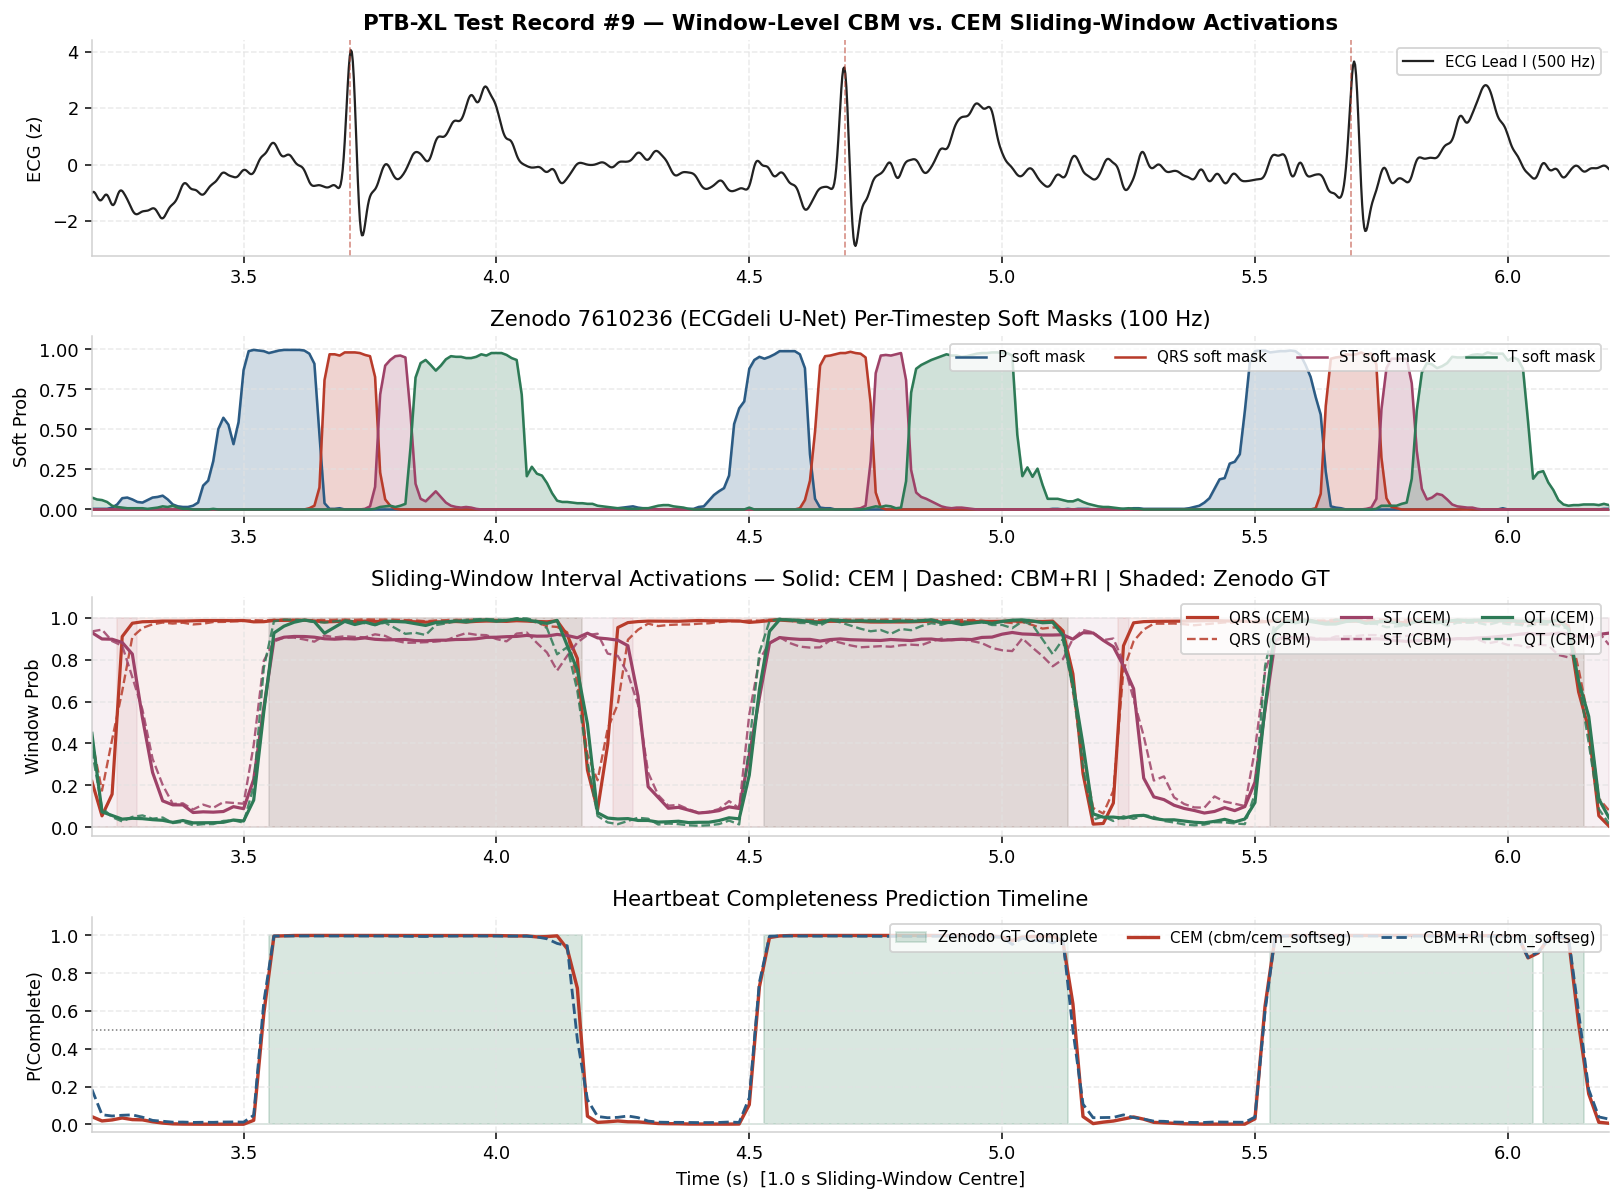

In [3]:
meta = pd.read_csv(DATA_PATH / "ptbxl_database.csv", index_col="ecg_id")
archive = SoftSegArchive(SOFT_SEG_PATH)

ECG_ID  = 9
SR      = 500
T_FIXED = 500
STRIDE  = 10
LEAD    = 0

raw_hr, _ = wfdb.rdsamp(str(DATA_PATH / meta.loc[ECG_ID, "filename_hr"]))
sig_500   = bandpass_filter(raw_hr.T.astype(np.float32), sampling_rate=SR)
sig_disp  = z_normalize(sig_500)

ss_raw = archive.load(ECG_ID)                                # (1000, 12, 24) @ 100 Hz
ss_env = soft_seg_to_wave_curves(ss_raw, lead_idx=LEAD)
ss_fid = extract_fiducials_from_soft_seg(ss_raw, lead_idx=LEAD)

starts  = np.arange(0, sig_500.shape[1] - T_FIXED + 1, STRIDE)
windows = np.stack([z_normalize(sig_500[:, s : s + T_FIXED]) for s in starts], axis=0).astype(np.float32)

gt_task, gt_conc = [], []
for s in starts:
    c, w = get_concept_labels(int(s), int(s + T_FIXED), ss_fid["delineation"], ss_fid["r_peaks"], None)
    gt_conc.append(c)
    gt_task.append(int(is_complete_heartbeat_window(c, w)))
gt_task = np.asarray(gt_task, dtype=np.float32)
gt_conc = np.asarray(gt_conc, dtype=np.float32)

@torch.no_grad()
def run_window_sweep(model, win_np):
    xb = torch.from_numpy(win_np).to(DEVICE)
    tp, cp, _ = model(xb)
    return tp.squeeze(-1).cpu().numpy(), cp.cpu().numpy()

cbm_t, cbm_c = run_window_sweep(cbm_model, windows)
cem_t, cem_c = run_window_sweep(cem_model, windows)

print(f"Record #{ECG_ID} | {len(starts)} windows (stride={STRIDE}) | R-peaks: {len(ss_fid['r_peaks'])}")
print(f"  Window Task Acc vs Zenodo GT — CBM: {((cbm_t > 0.5) == gt_task).mean():.4f} | CEM: {((cem_t > 0.5) == gt_task).mean():.4f}")

# 4-panel zoomed comparison (3.2s – 6.2s)
t_500 = np.arange(sig_500.shape[1]) / 500.0
t_100 = np.arange(ss_raw.shape[0]) / 100.0
t_win = (starts + T_FIXED // 2) / 500.0
t_lo, t_hi = 3.2, 6.2
m500, m100, mwin = (t_500 >= t_lo) & (t_500 <= t_hi), (t_100 >= t_lo) & (t_100 <= t_hi), (t_win >= t_lo) & (t_win <= t_hi)

fig = plt.figure(figsize=(14.5, 10.5))
gs = gridspec.GridSpec(4, 1, height_ratios=[1.8, 1.5, 2.0, 1.8], hspace=0.38)

ax0 = fig.add_subplot(gs[0])
ax0.plot(t_500[m500], sig_disp[LEAD, m500], color="#222222", lw=1.2, label="ECG Lead I (500 Hz)")
for idx_r, r in enumerate(ss_fid["r_peaks"]):
    rt = r / 500.0
    if t_lo <= rt <= t_hi:
        ax0.axvline(rt, color="#b83b2a", ls="--", lw=0.85, alpha=0.6, label="ECGdeli R-peak" if idx_r == 0 else None)
ax0.set_xlim(t_lo, t_hi); ax0.set_ylabel("ECG (z)")
ax0.set_title(f"PTB-XL Test Record #{ECG_ID} — Window-Level CBM vs. CEM Sliding-Window Activations", fontweight="bold")
ax0.legend(loc="upper right", fontsize=8)

ax1 = fig.add_subplot(gs[1], sharex=ax0)
for k, col in [("P", "#2b5b84"), ("QRS", "#b83b2a"), ("ST", "#9e4268"), ("T", "#2d7a56")]:
    ax1.fill_between(t_100[m100], 0, ss_env[k][m100], color=col, alpha=0.22)
    ax1.plot(t_100[m100], ss_env[k][m100], color=col, lw=1.35, label=f"{k} soft mask")
ax1.set_ylim(-0.04, 1.08); ax1.set_ylabel("Soft Prob")
ax1.set_title("Zenodo 7610236 (ECGdeli U-Net) Per-Timestep Soft Masks (100 Hz)")
ax1.legend(loc="upper right", ncol=4, fontsize=8)

ax2 = fig.add_subplot(gs[2], sharex=ax0)
for idx_k, name, col in [(7, "QRS", "#b83b2a"), (8, "ST", "#9e4268"), (9, "QT", "#2d7a56")]:
    ax2.fill_between(t_win[mwin], 0, gt_conc[mwin, idx_k], color=col, alpha=0.08, step="mid")
    ax2.plot(t_win[mwin], cem_c[mwin, idx_k], color=col, lw=1.7, ls="-",  label=f"{name} (CEM)")
    ax2.plot(t_win[mwin], cbm_c[mwin, idx_k], color=col, lw=1.25, ls="--", alpha=0.85, label=f"{name} (CBM)")
ax2.set_ylim(-0.04, 1.10); ax2.set_ylabel("Window Prob")
ax2.set_title("Sliding-Window Interval Activations — Solid: CEM | Dashed: CBM+RI | Shaded: Zenodo GT")
ax2.legend(loc="upper right", ncol=3, fontsize=8)

ax3 = fig.add_subplot(gs[3], sharex=ax0)
ax3.fill_between(t_win[mwin], 0, gt_task[mwin], color="#2d7a56", alpha=0.18, step="mid", label="Zenodo GT Complete")
ax3.plot(t_win[mwin], cem_t[mwin], color="#b83b2a", lw=1.8, label="CEM (cbm/cem_softseg)")
ax3.plot(t_win[mwin], cbm_t[mwin], color="#2b5b84", lw=1.5, ls="--", label="CBM+RI (cbm_softseg)")
ax3.axhline(0.5, color="#767676", ls=":", lw=0.8)
ax3.set_ylim(-0.04, 1.10); ax3.set_xlabel("Time (s)  [1.0 s Sliding-Window Centre]"); ax3.set_ylabel("P(Complete)")
ax3.set_title("Heartbeat Completeness Prediction Timeline")
ax3.legend(loc="upper right", ncol=3, fontsize=8)
plt.show()

## 3 — Window-Level Concept Interventions, Faithfulness & Concept Importance

Both **CBM + RandInt** and **CEM** support causal test-time interventions: overriding predicted concept activations directly steers the heartbeat completeness prediction. Below we run live counterfactual overrides on a Complete and Incomplete window from Record `#9`, and plot the full Test Fold 10 intervention curves (uncertainty-guided vs. random order).

── Live Counterfactual Concept Interventions on Record #9 ──
           Model  Complete Base  Complete → All=0  Complete → QT=0  Incomplete Base  Incomplete → All=1  Incomplete → QT=1
CBM+RI (SoftSeg)         0.9956            0.0962           0.7956           0.0350               0.881             0.6981
   CEM (SoftSeg)         0.9997            0.0000           0.0000           0.0038               1.000             1.0000


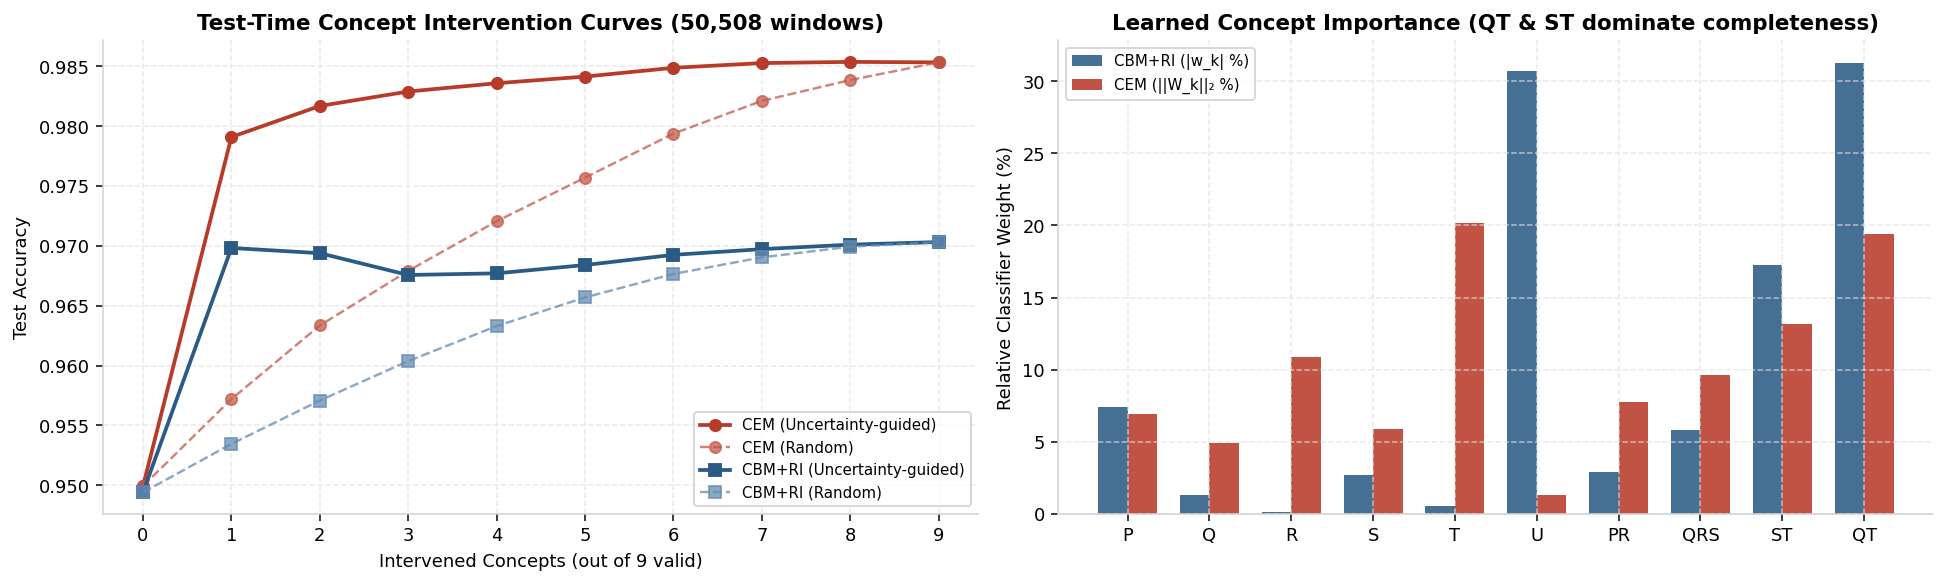

In [4]:
# Pick one clear Complete window and one clear Incomplete window on Record #9
idx_cmp = int(np.where((gt_task == 1) & (cem_t > 0.9))[0][len(np.where((gt_task == 1) & (cem_t > 0.9))[0]) // 2])
idx_inc = int(np.where((gt_task == 0) & (cem_t < 0.1))[0][len(np.where((gt_task == 0) & (cem_t < 0.1))[0]) // 2])

x_pair = torch.from_numpy(windows[[idx_cmp, idx_inc]]).to(DEVICE)
valid_mask = torch.ones((2, 10), device=DEVICE)
valid_mask[:, 5] = 0.0  # U-wave masked on soft_seg models

rows_cf = []
for name, m in [("CBM+RI (SoftSeg)", cbm_model), ("CEM (SoftSeg)", cem_model)]:
    with torch.no_grad():
        p_base, _, _ = m(x_pair)
        p_zero = m.intervene(x_pair, torch.zeros_like(valid_mask), valid_mask)
        p_one  = m.intervene(x_pair, torch.ones_like(valid_mask),  valid_mask)
        # Single-concept intervention: flip QT (idx=9) only
        m_qt = torch.zeros_like(valid_mask); m_qt[:, 9] = 1.0
        p_qt0 = m.intervene(x_pair, torch.zeros_like(valid_mask), m_qt)
        p_qt1 = m.intervene(x_pair, torch.ones_like(valid_mask),  m_qt)
    rows_cf.append({
        "Model": name,
        "Complete Base": round(float(p_base[0]), 4),
        "Complete → All=0": round(float(p_zero[0]), 4),
        "Complete → QT=0": round(float(p_qt0[0]), 4),
        "Incomplete Base": round(float(p_base[1]), 4),
        "Incomplete → All=1": round(float(p_one[1]), 4),
        "Incomplete → QT=1": round(float(p_qt1[1]), 4),
    })

print("── Live Counterfactual Concept Interventions on Record #9 ──")
print(pd.DataFrame(rows_cf).to_string(index=False))

# Plot Test-Set Intervention Curves + Concept Importance Weights
int_cbm = json.loads((CBM_DIR / "intervention_test.json").read_text())
int_cem = json.loads((CEM_DIR / "intervention_test.json").read_text())

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.4))

ax = axes[0]
ks = int_cem["num_intervened"][:10]
ax.plot(ks, int_cem["uncertainty_acc"][:10], marker="o", lw=2.0, color="#b83b2a", label="CEM (Uncertainty-guided)")
ax.plot(ks, int_cem["random_acc"][:10],      marker="o", lw=1.3, ls="--", color="#c45a4b", alpha=0.75, label="CEM (Random)")
ax.plot(ks, int_cbm["uncertainty_acc"][:10], marker="s", lw=2.0, color="#2b5b84", label="CBM+RI (Uncertainty-guided)")
ax.plot(ks, int_cbm["random_acc"][:10],      marker="s", lw=1.3, ls="--", color="#648cb2", alpha=0.75, label="CBM+RI (Random)")
ax.set_xticks(ks); ax.set_xlabel("Intervened Concepts (out of 9 valid)"); ax.set_ylabel("Test Accuracy")
ax.set_title("Test-Time Concept Intervention Curves (50,508 windows)", fontweight="bold")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
w_cbm = cbm_model.get_concept_importance(CONCEPT_NAMES)
w_cem = cem_model.get_concept_importance(CONCEPT_NAMES)
x = np.arange(len(CONCEPT_NAMES)); bw = 0.36
vals_cbm = [abs(w_cbm[c]["prob_weight"]) for c in CONCEPT_NAMES]
vals_cem = [abs(w_cem[c]["prob_weight"]) for c in CONCEPT_NAMES]
# Normalize to relative share (%) so scalar CBM weights and L2 CEM block norms compare cleanly
vals_cbm = np.array(vals_cbm) / (np.sum(vals_cbm) + 1e-8) * 100.0
vals_cem = np.array(vals_cem) / (np.sum(vals_cem) + 1e-8) * 100.0
ax.bar(x - bw/2, vals_cbm, bw, color="#2b5b84", alpha=0.88, label="CBM+RI (|w_k| %)")
ax.bar(x + bw/2, vals_cem, bw, color="#b83b2a", alpha=0.88, label="CEM (||W_k||₂ %)")
ax.set_xticks(x); ax.set_xticklabels(CONCEPT_NAMES)
ax.set_ylabel("Relative Classifier Weight (%)")
ax.set_title("Learned Concept Importance (QT & ST dominate completeness)", fontweight="bold")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 4 — Per-Timestamp Dense Soft-Segmentation CBM & CEM (`100 Hz` = `10 ms` Resolution)

Instead of pooling a 1.0 s window into a single global vector, **`DenseSoftSegCBM`** and **`DenseSoftSegCEM`** (`src/dense_seg.py`) use a **1D Residual U-Net** to predict soft wave concepts (`P, PQ, QRS, ST, T, TP`) and epistemic + aleatoric uncertainty **at every timestamp**, routing the per-timestamp bottleneck into a downstream **5-class PTB-XL cardiac pathology head** (`NORM, MI, STTC, CD, HYP`).

── Live Per-Timestamp Mask Interventions on Record #9 (5-Class Pathology) ──
          Model   Intervention  NORM    MI  STTC    CD   HYP
DenseSoftSegCEM       Baseline 0.933 0.024 0.006 0.041 0.023
DenseSoftSegCEM Apply GT Masks 0.934 0.022 0.006 0.039 0.022
DenseSoftSegCEM  Ablate ST → 0 0.928 0.023 0.005 0.035 0.021
DenseSoftSegCBM       Baseline 0.967 0.003 0.007 0.030 0.017
DenseSoftSegCBM Apply GT Masks 0.933 0.009 0.016 0.046 0.024
DenseSoftSegCBM  Ablate ST → 0 0.985 0.000 0.000 0.958 0.001


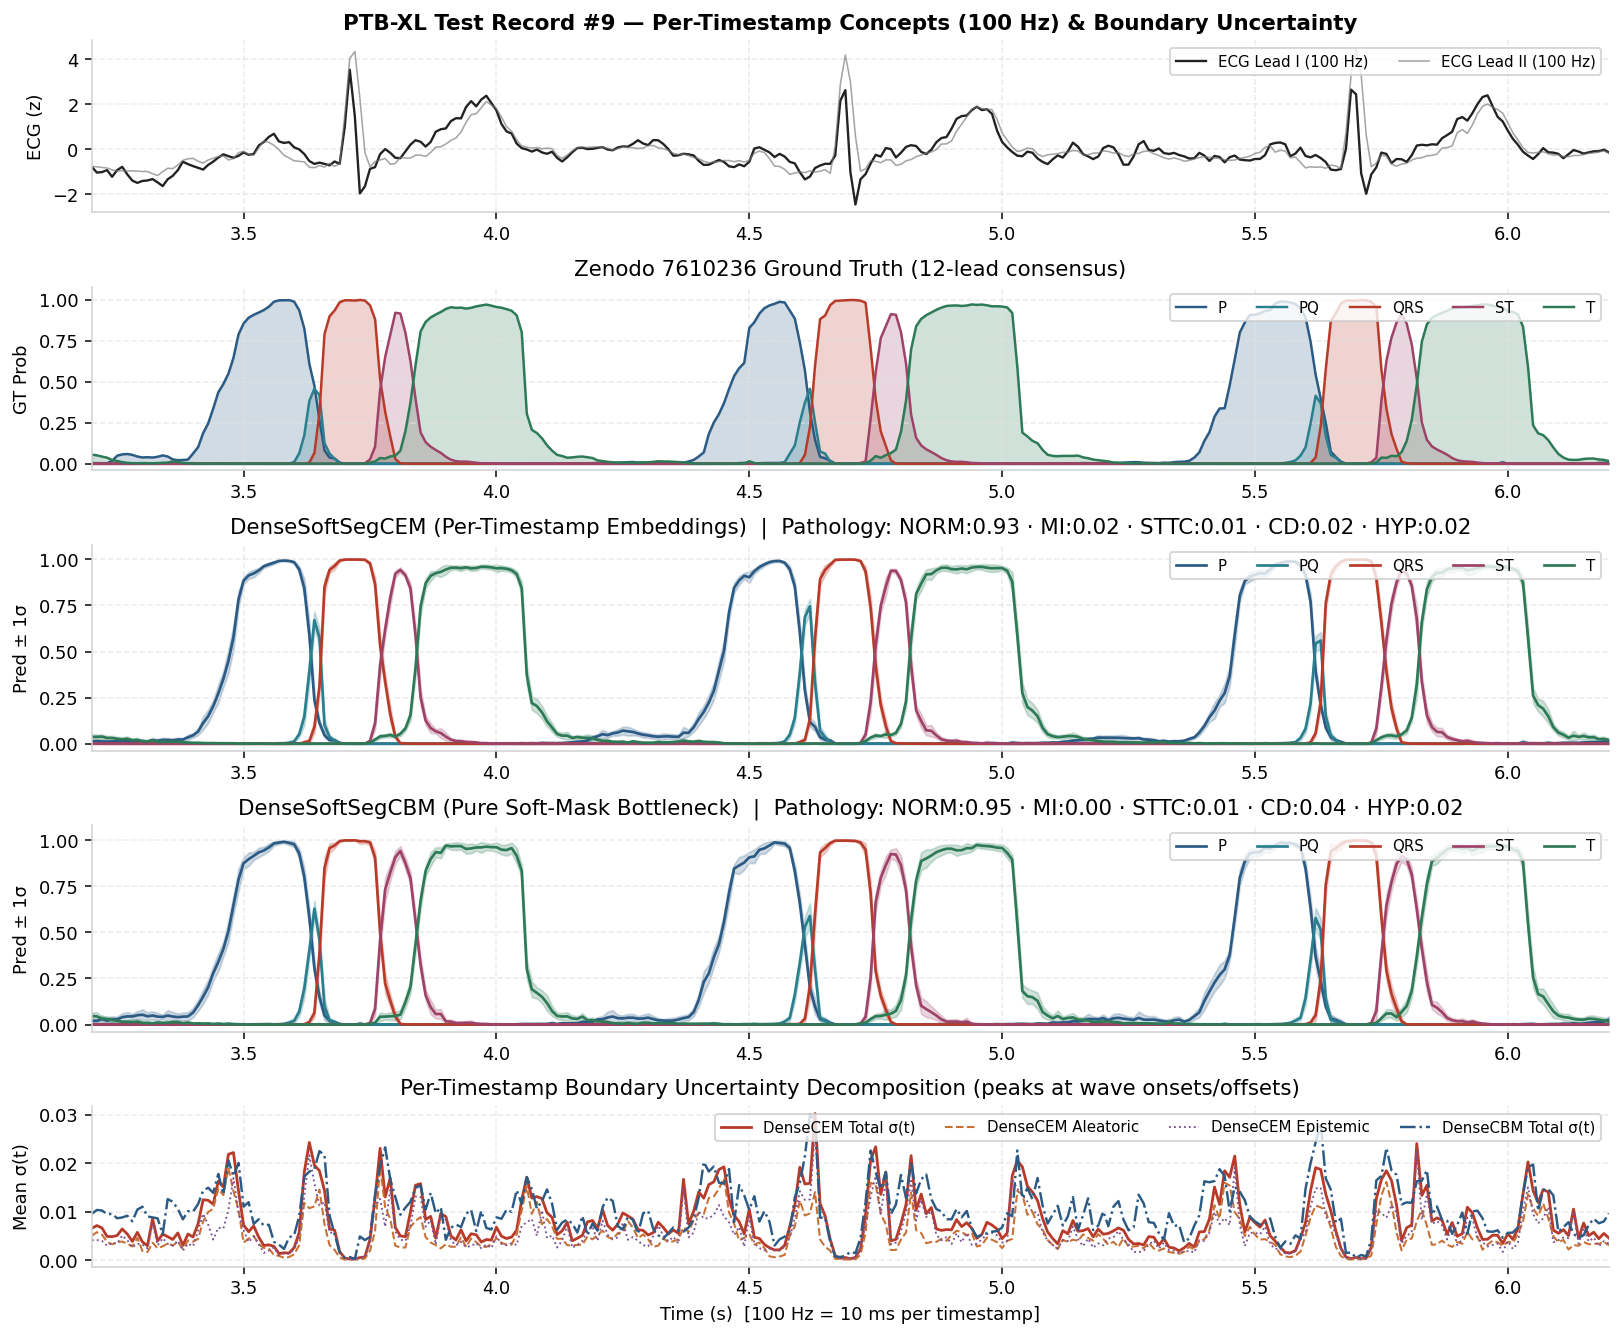

In [5]:
raw_lr, _ = wfdb.rdsamp(str(DATA_PATH / meta.loc[ECG_ID, "filename_lr"]))
sig_100   = z_normalize(bandpass_filter(raw_lr.T.astype(np.float32), sampling_rate=100))
gt_wave6  = collapse_soft_seg_targets(ss_raw, concept_mode="wave6", lead_idx=None)  # (6, 1000)

x_100 = torch.from_numpy(sig_100).unsqueeze(0).to(DEVICE)
unc_cem = dense_cem_model.predict_with_uncertainty(x_100, n_mc_epistemic=12, n_mc_aleatoric=20)
unc_cbm = dense_cbm_model.predict_with_uncertainty(x_100, n_mc_epistemic=12, n_mc_aleatoric=20)

cem_p, cem_s = unc_cem["concept_probs_mean"][0].cpu().numpy(), unc_cem["concept_total_std"][0].cpu().numpy()
cem_al, cem_ep = unc_cem["concept_aleatoric"][0].cpu().numpy(), unc_cem["concept_epistemic"][0].cpu().numpy()
cbm_p, cbm_s = unc_cbm["concept_probs_mean"][0].cpu().numpy(), unc_cbm["concept_total_std"][0].cpu().numpy()
cem_patho = unc_cem["task_probs_mean"][0].cpu().numpy()
cbm_patho = unc_cbm["task_probs_mean"][0].cpu().numpy()

t100 = np.arange(1000) / 100.0
mz = (t100 >= t_lo) & (t100 <= t_hi)
wave_cols = {"P": "#2b5b84", "PQ": "#2a7f8e", "QRS": "#b83b2a", "ST": "#9e4268", "T": "#2d7a56"}
show_w = [(0, "P"), (1, "PQ"), (2, "QRS"), (3, "ST"), (4, "T")]

fig = plt.figure(figsize=(14.5, 11.8))
gs = gridspec.GridSpec(5, 1, height_ratios=[1.5, 1.6, 1.8, 1.8, 1.4], hspace=0.40)

ax0 = fig.add_subplot(gs[0])
ax0.plot(t100[mz], sig_100[0, mz], color="#222222", lw=1.25, label="ECG Lead I (100 Hz)")
ax0.plot(t100[mz], sig_100[1, mz], color="#767676", lw=0.85, alpha=0.65, label="ECG Lead II (100 Hz)")
ax0.set_xlim(t_lo, t_hi); ax0.set_ylabel("ECG (z)")
ax0.set_title(f"PTB-XL Test Record #{ECG_ID} — Per-Timestamp Concepts (100 Hz) & Boundary Uncertainty", fontweight="bold")
ax0.legend(loc="upper right", ncol=2, fontsize=8)

ax1 = fig.add_subplot(gs[1], sharex=ax0)
for k, name in show_w:
    c = wave_cols[name]
    ax1.fill_between(t100[mz], 0, gt_wave6[k, mz], color=c, alpha=0.22)
    ax1.plot(t100[mz], gt_wave6[k, mz], color=c, lw=1.3, label=name)
ax1.set_ylim(-0.04, 1.08); ax1.set_ylabel("GT Prob")
ax1.set_title("Zenodo 7610236 Ground Truth (12-lead consensus)")
ax1.legend(loc="upper right", ncol=5, fontsize=8)

ax2 = fig.add_subplot(gs[2], sharex=ax0)
for k, name in show_w:
    c = wave_cols[name]
    mu, sd = cem_p[k, mz], cem_s[k, mz]
    ax2.fill_between(t100[mz], np.clip(mu - sd, 0, 1), np.clip(mu + sd, 0, 1), color=c, alpha=0.22)
    ax2.plot(t100[mz], mu, color=c, lw=1.45, label=name)
pstr = " · ".join(f"{n}:{v:.2f}" for n, v in zip(SUPERCLASS_NAMES, cem_patho))
ax2.set_ylim(-0.04, 1.08); ax2.set_ylabel("Pred ± 1σ")
ax2.set_title(f"DenseSoftSegCEM (Per-Timestamp Embeddings)  |  Pathology: {pstr}")
ax2.legend(loc="upper right", ncol=5, fontsize=8)

ax3 = fig.add_subplot(gs[3], sharex=ax0)
for k, name in show_w:
    c = wave_cols[name]
    mu, sd = cbm_p[k, mz], cbm_s[k, mz]
    ax3.fill_between(t100[mz], np.clip(mu - sd, 0, 1), np.clip(mu + sd, 0, 1), color=c, alpha=0.22)
    ax3.plot(t100[mz], mu, color=c, lw=1.45, label=name)
pstr_b = " · ".join(f"{n}:{v:.2f}" for n, v in zip(SUPERCLASS_NAMES, cbm_patho))
ax3.set_ylim(-0.04, 1.08); ax3.set_ylabel("Pred ± 1σ")
ax3.set_title(f"DenseSoftSegCBM (Pure Soft-Mask Bottleneck)  |  Pathology: {pstr_b}")
ax3.legend(loc="upper right", ncol=5, fontsize=8)

ax4 = fig.add_subplot(gs[4], sharex=ax0)
ax4.plot(t100[mz], cem_s[:, mz].mean(axis=0),  color="#b83b2a", lw=1.5, label="DenseCEM Total σ(t)")
ax4.plot(t100[mz], cem_al[:, mz].mean(axis=0), color="#c87137", lw=1.1, ls="--", label="DenseCEM Aleatoric")
ax4.plot(t100[mz], cem_ep[:, mz].mean(axis=0), color="#7c5295", lw=1.0, ls=":",  label="DenseCEM Epistemic")
ax4.plot(t100[mz], cbm_s[:, mz].mean(axis=0),  color="#2b5b84", lw=1.3, ls="-.", label="DenseCBM Total σ(t)")
ax4.set_xlabel("Time (s)  [100 Hz = 10 ms per timestamp]"); ax4.set_ylabel("Mean σ(t)")
ax4.set_title("Per-Timestamp Boundary Uncertainty Decomposition (peaks at wave onsets/offsets)")
ax4.legend(loc="upper right", ncol=4, fontsize=8)
plt.show()

# Live per-timestamp mask interventions: GT masks, Ablate ST, Force QRS on [350:450]
gt_t = torch.from_numpy(gt_wave6).unsqueeze(0).to(DEVICE)
full_mask = torch.ones((1, 1, 1000), device=DEVICE)

int_rows = []
for mname, m in [("DenseSoftSegCEM", dense_cem_model), ("DenseSoftSegCBM", dense_cbm_model)]:
    with torch.no_grad():
        base = m(x_100)
        p_base = torch.sigmoid(base["task_logits"][0]).cpu().numpy()
        p_gt   = torch.sigmoid(m.intervene(x_100, gt_t, full_mask)["task_logits"][0]).cpu().numpy()
        ab_st  = base["concept_probs"].clone(); ab_st[:, 3, :] = 0.0
        mk_st  = torch.zeros_like(ab_st); mk_st[:, 3, :] = 1.0
        p_st0  = torch.sigmoid(m.intervene(x_100, ab_st, mk_st)["task_logits"][0]).cpu().numpy()
    for mode_lbl, vec in [("Baseline", p_base), ("Apply GT Masks", p_gt), ("Ablate ST → 0", p_st0)]:
        row = {"Model": mname, "Intervention": mode_lbl}
        for cname, v in zip(SUPERCLASS_NAMES, vec):
            row[cname] = round(float(v), 3)
        int_rows.append(row)

print("── Live Per-Timestamp Mask Interventions on Record #9 (5-Class Pathology) ──")
print(pd.DataFrame(int_rows).to_string(index=False))

## 5 — Challenging Clinical ECGs (AFIB, LBBB/RBBB, Acute MI / STTC)

Finally, we compare **Window-Level CEM** (`cem_softseg`) and **Per-Timestamp Dense CEM** (`dense_cem_softseg`) side-by-side on three clinically challenging Fold-10 test ECGs: Atrial Fibrillation (`AFIB` — absent P-waves), Bundle Branch Block (`BBB` — wide QRS), and Myocardial Infarction (`MI` — abnormal ST-T morphology).

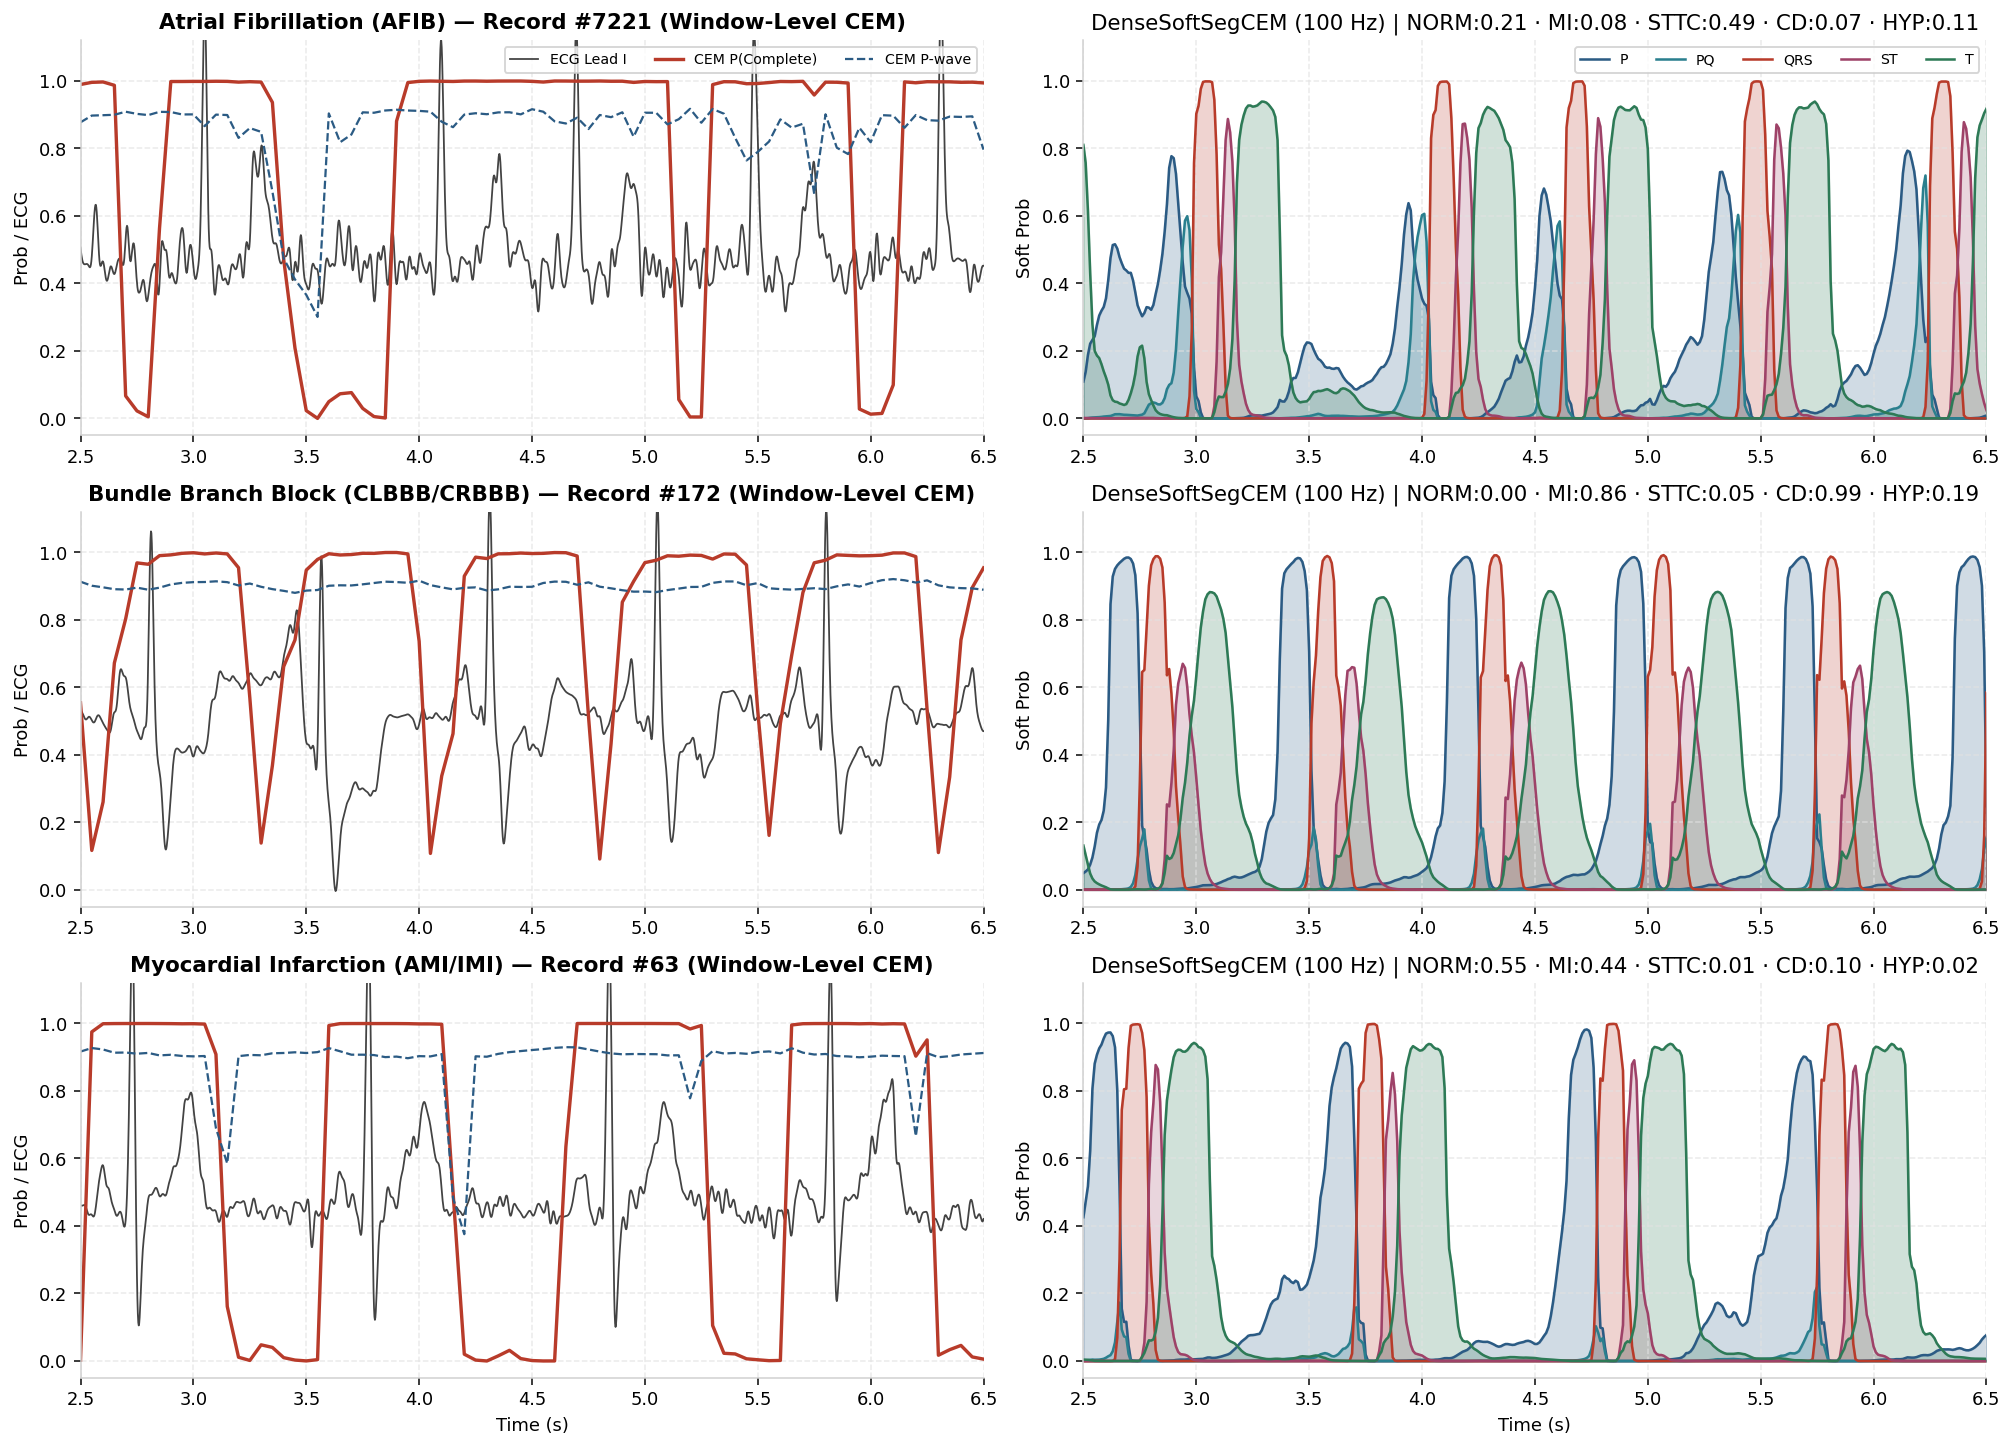

In [6]:
def has_any_code(scp_str: str, targets: set) -> bool:
    try:
        codes = {k for k, v in ast.literal_eval(str(scp_str)).items() if v > 0}
        return not codes.isdisjoint(targets)
    except Exception:
        return False

test_meta = meta[meta["strat_fold"] == 10]
groups = [
    ("Atrial Fibrillation (AFIB)", {"AFIB"}),
    ("Bundle Branch Block (CLBBB/CRBBB)", {"CLBBB", "CRBBB"}),
    ("Myocardial Infarction (AMI/IMI)", {"AMI", "IMI", "ASMI"}),
]

chosen = []
for title, codes in groups:
    sub = test_meta[test_meta["scp_codes"].apply(lambda s: has_any_code(s, codes))]
    for eid in sub.index:
        if int(eid) in archive:
            chosen.append((title, int(eid)))
            break

fig, axes = plt.subplots(len(chosen), 2, figsize=(15.0, 3.6 * len(chosen)), sharex=False)
for row_i, (title, eid) in enumerate(chosen):
    raw_h, _ = wfdb.rdsamp(str(DATA_PATH / meta.loc[eid, "filename_hr"]))
    raw_l, _ = wfdb.rdsamp(str(DATA_PATH / meta.loc[eid, "filename_lr"]))
    s500 = bandpass_filter(raw_h.T.astype(np.float32), 500)
    s100 = z_normalize(bandpass_filter(raw_l.T.astype(np.float32), 100))

    # Window-level CEM sweep (stride=25)
    st_arr = np.arange(0, s500.shape[1] - 500 + 1, 25)
    w_np = np.stack([z_normalize(s500[:, s : s + 500]) for s in st_arr], axis=0).astype(np.float32)
    tp_w, cp_w = run_window_sweep(cem_model, w_np)

    # Per-timestamp Dense CEM (100 Hz)
    with torch.no_grad():
        d_out = dense_cem_model(torch.from_numpy(s100).unsqueeze(0).to(DEVICE))
        dp = d_out["concept_probs"][0].cpu().numpy()
        dt = torch.sigmoid(d_out["task_logits"][0]).cpu().numpy()

    # Zoom 2.5s – 6.5s
    zl, zh = 2.5, 6.5
    t5 = np.arange(s500.shape[1]) / 500.0
    tw = (st_arr + 250) / 500.0
    t1 = np.arange(1000) / 100.0
    m5, mw, m1 = (t5 >= zl) & (t5 <= zh), (tw >= zl) & (tw <= zh), (t1 >= zl) & (t1 <= zh)

    # Left: ECG + Window CEM completeness & QT/ST
    axL = axes[row_i, 0]
    axL.plot(t5[m5], z_normalize(s500)[0, m5] * 0.14 + 0.5, color="#222222", lw=0.95, alpha=0.85, label="ECG Lead I")
    axL.plot(tw[mw], tp_w[mw], color="#b83b2a", lw=1.8, label="CEM P(Complete)")
    axL.plot(tw[mw], cp_w[mw, 0], color="#2b5b84", lw=1.2, ls="--", label="CEM P-wave")
    axL.set_xlim(zl, zh); axL.set_ylim(-0.05, 1.12)
    axL.set_ylabel("Prob / ECG")
    axL.set_title(f"{title} — Record #{eid} (Window-Level CEM)", fontweight="bold")
    if row_i == 0:
        axL.legend(loc="upper right", ncol=3, fontsize=7.5)

    # Right: Per-timestamp Dense CEM soft segmentation + 5-class Pathology
    axR = axes[row_i, 1]
    for k, name in show_w:
        c = wave_cols[name]
        axR.fill_between(t1[m1], 0, dp[k, m1], color=c, alpha=0.22)
        axR.plot(t1[m1], dp[k, m1], color=c, lw=1.35, label=name)
    p_str = " · ".join(f"{n}:{v:.2f}" for n, v in zip(SUPERCLASS_NAMES, dt))
    axR.set_xlim(zl, zh); axR.set_ylim(-0.05, 1.12); axR.set_ylabel("Soft Prob")
    axR.set_title(f"DenseSoftSegCEM (100 Hz) | {p_str}")
    if row_i == 0:
        axR.legend(loc="upper right", ncol=5, fontsize=7.5)
    if row_i == len(chosen) - 1:
        axL.set_xlabel("Time (s)"); axR.set_xlabel("Time (s)")

plt.tight_layout()
plt.show()
archive.close()